# code_044 · Subgroups, rare cases and coverage

**Book:** section 9.3. A self-contained exploration laboratory using invented building, load and sensor records. Prerequisites: arrays/tables and Chapter 8's case, timing and schema contracts. Restart and run all cells; all imports, helpers and generated inputs are here. Ordinary execution needs no files, network, keys, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_09_GUIDE.md), [execution evidence](../CHAPTER_09_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_044).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow one minute to run and 30–60 minutes to interpret. These scoped concept experiments disclose data/task controls rather than claim exhaustive estimator API coverage. Plots and construction identities are exploratory diagnostics, not independent predictive evidence. Only the hypothesis laboratory fits competing predictors, selects on development buildings and opens a protected final set after freezing its rule. All evidence is synthetic, with no structural-safety, population-calibration or causal claim.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=944;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 944


<a id="counts"></a>
## A large table can contain almost no evidence for an important group

Construct three independent-structure groups: ordinary connections (240 cases), uncommon connections (40) and novel connections (6). The binary quantity is whether a fixed alarm rule misses an author-generated finding among these positive finding cases. It is a conditional miss rate, not failure prevalence. Miss probabilities .08/.15/.20 define the simulator. A fourth approved schema category has zero examples. A separate constructed cohort count is 600/100/10 structures, with exactly 240/40/6 reference findings; those fixed counts describe class prevalence, while the Bernoulli experiment models misses conditional on findings. Each finding case contributes one independent miss outcome in this lab; repeated sensor rows would require another uncertainty calculation.

Predeclare the groups before outcomes. Do not search thousands of slices and label the most extreme one a confirmed finding. Unknown labels and groups with no positive finding denominator cannot receive a manufactured zero miss rate.


,group,cohort_structures,reference_findings,finding_prevalence,misses,conditional_miss_rate
0,Ordinary,600,240,0.4,18,0.075000
1,Uncommon,100,40,0.4,7,0.175000
2,Novel,10,6,0.6,2,0.333333


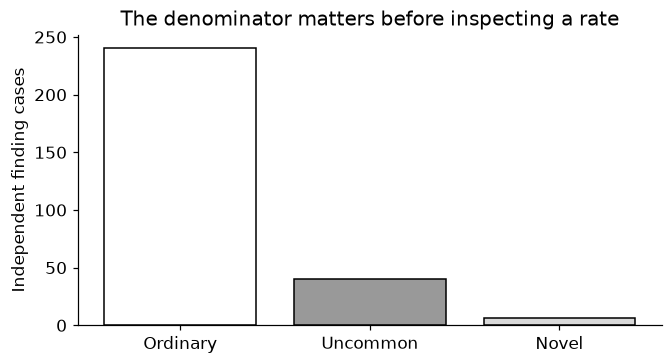

In [2]:
n=np.array([240,40,6]);groups=['Ordinary','Uncommon','Novel'];p=np.array([.08,.15,.20]);miss=np.array([rng.binomial(int(nn),pp) for nn,pp in zip(n,p)])
assert n.sum()==286 and np.all(miss<=n) and np.all(miss>=0)
cohort_n=np.array([600,100,10]);assert np.all(n<=cohort_n)
frame=pd.DataFrame({'group':groups,'cohort_structures':cohort_n,'reference_findings':n,'finding_prevalence':n/cohort_n,'misses':miss,'conditional_miss_rate':miss/n});display(frame)
RESULTS['cohort_counts']=dict(zip(groups,cohort_n.tolist()));RESULTS['constructed_finding_prevalence']=dict(zip(groups,(n/cohort_n).tolist()))
schema_counts={**dict(zip(groups,n.tolist())),'Unseen approved type':0};assert schema_counts['Unseen approved type']==0
fig,ax=plt.subplots(figsize=(6,3.2));ax.bar(groups,n,color=['white','.6','.85'],edgecolor='black');ax.set(ylabel='Independent finding cases',title='The denominator matters before inspecting a rate');plt.show()
RESULTS['counts']=dict(zip(groups,n.tolist()));RESULTS['misses']=dict(zip(groups,miss.tolist()));RESULTS['observed_miss_rates']=dict(zip(groups,(miss/n).tolist()));RESULTS['unseen_category_count']=0


<a id="intervals"></a>
## An interval is a conditional uncertainty statement

Compute two-sided 95% Wilson score intervals under independent Bernoulli sampling within each prespecified group. z=1.959963984540054 is fixed; the center is (p_hat+z²/(2n))/(1+z²/n) and half-width is z*sqrt(p_hat*(1-p_hat)/n+z²/(4n²))/(1+z²/n). These intervals do not account for selected slices, dependence, label errors or population shift. Small-sample coverage is not asserted to be exactly .95. No new alarm rule is fitted or selected here.


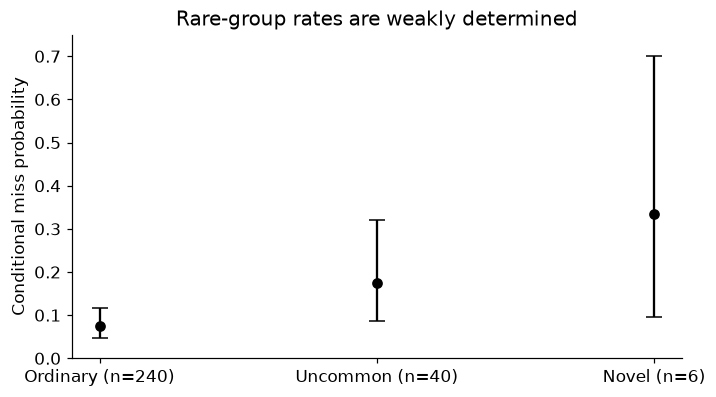

In [3]:
def wilson(k,n,z=1.959963984540054):
 k=np.asarray(k,dtype=float);n=np.asarray(n,dtype=float);assert np.all(n>0) and np.all((k>=0)&(k<=n))
 ph=k/n;den=1+z*z/n;center=(ph+z*z/(2*n))/den;half=z*np.sqrt(ph*(1-ph)/n+z*z/(4*n*n))/den
 return np.maximum(0,center-half),np.minimum(1,center+half)
lo,hi=wilson(miss,n);assert np.all(lo<=miss/n) and np.all(hi>=miss/n)
zero_lo,zero_hi=wilson(0,6);assert np.isclose(zero_lo,0) and zero_hi>.35
fig,ax=plt.subplots(figsize=(6.4,3.5));rate=miss/n;ax.errorbar(np.arange(3),rate,yerr=[rate-lo,hi-rate],fmt='ko',capsize=5);ax.set(xticks=np.arange(3),xticklabels=[f'{g} (n={nn})' for g,nn in zip(groups,n)],ylabel='Conditional miss probability',ylim=(0,max(.65,float(hi.max())+.05)),title='Rare-group rates are weakly determined');plt.show()
RESULTS['Wilson_95_intervals']={g:[float(a),float(b)] for g,a,b in zip(groups,lo,hi)};RESULTS['zero_of_six_Wilson_upper']=float(zero_hi)


<a id="coverage"></a>
## Repeated rows are not new independent cases

Duplicate each novel-connection outcome twenty times, as if twenty sensor readings carried the same finding. A naïve independent-row Wilson interval becomes narrower without any new structure outcome. This is an intentionally invalid counterexample, not an alternative valid confidence interval. Acquisition priorities require consequences and costs as well as counts; those decision values are not invented here. A missing category means no direct evidence, not demonstrated poor or good performance.


In [4]:
naive_lo,naive_hi=wilson(int(miss[-1])*20,int(n[-1])*20);assert float(naive_hi-naive_lo)<float(hi[-1]-lo[-1])
assert n[-1]==6 and n[-1]*20==120
RESULTS['novel_true_independent_count']=6;RESULTS['novel_duplicated_rows']=120;RESULTS['invalid_row_interval']=[float(naive_lo),float(naive_hi)]
RESULTS['coverage_record']={'observed_unit':'one independent structure with a reference finding','unseen_type':'no miss-rate denominator','slice_policy':'three prespecified operational groups','limits':['independent Bernoulli assumptions','simulated labels','no field calibration','no consequences supplied']}


<a id="exercises"></a>
## Exercises and hints

1. If zero of six cases are missed, compare the point estimate with the Wilson upper endpoint before claiming adequacy.
2. Supply deployment group weights and compare overall rate with equal-group averaging.
3. Add uncertain labels or repeated inspections and state which interval assumptions fail.
4. Write an acquisition question for a rare high-consequence connection type without inventing its real risk or cost.

**Hints:** missing classes, six cases and a hundred repeated rows have different meanings. Do not interpret a confidence interval as a guarantee about the next structure or a probability that an unknown fixed rate lies inside a realized interval. More formal uncertainty, fairness and decision analyses occur later in the book.


In [5]:
summary={'example_id':'code_044','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['counts and prevalence by operational group', 'rare-group zero-event uncertainty', 'Wilson interval assumptions and limits', 'row counts versus independent structures', 'unobserved schema categories'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["counts and prevalence by operational group", "rare-group zero-event uncertainty", "Wilson interval assumptions and limits", "row counts versus independent structures", "unobserved schema categories"], "elapsed_seconds": 0.092, "example_id": "code_044", "hardware": "Darwin arm64 CPU", "results": {"Wilson_95_intervals": {"Novel": [0.09677141110578041, 0.700006684861608], "Ordinary": [0.04796476535845924, 0.11542606659186576], "Uncommon": [0.0874541374603592, 0.31949990331787714]}, "cohort_counts": {"Novel": 10, "Ordinary": 600, "Uncommon": 100}, "constructed_finding_prevalence": {"Novel": 0.6, "Ordinary": 0.4, "Uncommon": 0.4}, "counts": {"Novel": 6, "Ordinary": 240, "Uncommon": 40}, "coverage_record": {"limits": ["independent Bernoulli assumptions", "simulated labels", "no field calibration", "no consequences supplied"], "observed_unit": "one independent structure with a reference finding", "slice_policy": "three prespecified operationa